In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import copy as cp
import math

In [3]:
train = pd.read_csv(r"C:\Users\SHREYAS ROY\Desktop\Manipal Work Documents\crime_train.csv")
test = pd.read_csv(r"C:\Users\SHREYAS ROY\Desktop\Manipal Work Documents\crime_test.csv")   #File is NOT in same directory as Jupyter Notebook

train = train.dropna() #can be changed later to fillna() with mean, median, forward/backward fill, *forward/backward mean fill
#print(train.head())
test = test.dropna()
train = pd.get_dummies(train, columns = ['city','weapon','sex','domain','crime_description'], drop_first = True)
train = train.drop(['Unnamed: 0', 'Num'], axis = 1) # Unnamed and Num are dependant features and are not related to our target column

test = pd.get_dummies(test, columns = ['city','weapon','sex','domain','crime_description'], drop_first = True)
test = test.drop(['Unnamed: 0', 'Num'], axis = 1)

train['case_filed'] = pd.to_datetime(train['case_filed'])
train['hour'] = train['case_filed'].dt.hour
train['day_of_week'] = train['case_filed'].dt.dayofweek  # Monday = 0, Sunday = 6
train['month'] = train['case_filed'].dt.month
train = pd.get_dummies(train, columns = ['hour','day_of_week','month'], drop_first = True) # to prevent 0 vs 23 disparity..

test['case_filed'] = pd.to_datetime(test['case_filed'])
test['hour'] = test['case_filed'].dt.hour
test['day_of_week'] = test['case_filed'].dt.dayofweek  # Monday = 0, Sunday = 6
test['month'] = test['case_filed'].dt.month
test = pd.get_dummies(test, columns = ['hour','day_of_week','month'], drop_first = True)
# We ignore year since that doesn't affect if a case is open or closed, also extrapolation failure might occur.

test = test.reindex(columns=train.columns, fill_value=0) # To Align columns of test wrt train(because we ran one hot encoding)

In [4]:
targetCol = 'closed'
train[targetCol] = train[targetCol].map({'Yes': 1, 'No': 0})
test[targetCol] = test[targetCol].map({'Yes': 1, 'No': 0})

rawFeatures = train.drop(columns = [targetCol, 'case_filed']).to_numpy()
target = train[targetCol].to_numpy().reshape(-1) # reshape() is used to avoid Broadcasting Mismatch
rawTestFeatures = test.drop(columns = [targetCol, 'case_filed']).to_numpy()
testCases = test[targetCol].to_numpy().reshape(-1)

In [5]:
rawFeatures = rawFeatures.astype(np.float64) #Originally dtype was 'object' instead of float
rawTestFeatures = rawTestFeatures.astype(np.float64)

# Z-Score Normalization
mean = np.mean(rawFeatures, axis=0)
std = np.std(rawFeatures, axis=0)
features = (rawFeatures - mean) / std # Assume std can never be 0

testFeatures = (rawTestFeatures - mean) / std
# There is a case to be made for one hot encoded features to be exempt from normalization, but for Z-Score normalization, it doesnt matter 
# (it is reversible since the weights in logistic regression will rearrage themselves)

In [6]:
def costFunction(x, y, w, b) -> float:
    m = x.shape[0]
    f_wb = np.dot(x,w) + b 
    #f_wb = np.clip(f_wb, -500, 500)
    g_wb = 1 / (1 + np.exp(-f_wb)) 
    #g_wb = np.clip(g_wb, 1e-15, 1 - 1e-15)
    
    cost = - np.dot(y, np.log(g_wb)) - np.dot((1 - y) , np.log(1 - g_wb))
    totalCost = np.sum(cost) / m
    return totalCost

In [7]:
def computeGradient(x, y, w, b) -> tuple:
    m = x.shape[0]
    dw, db = 0, 0
    f_wb = np.dot(x,w) + b 
    #f_wb = np.clip(f_wb, -500, 500)
    g_wb = 1 / (1 + np.exp(-f_wb))
    #g_wb = np.clip(g_wb, 1e-15, 1 - 1e-15)
    error = g_wb - y
    dw = np.dot(x.T, error) / m
    db = np.sum(error) / m
    return dw, db

In [9]:
def gradientDescent(features, target, wIn, b, alpha, iterations) -> tuple:
    m = features.shape[0]
    J_history = [] #For Graphing purposes:
    w = cp.deepcopy(wIn)
    for i in range(0, iterations + 1):
        dw, db = computeGradient(features, target, w, b)
        w = w - alpha * dw
        b = b - alpha * db
        cost = costFunction(features, target, w, b)
        J_history.append(cost)
        if i % (iterations // 10) == 0:
            print(f"Iteration {i:4}: Cost {float(J_history[-1]): .6f}   ")
    return w, b, J_history

In [16]:
wIn = np.zeros(features.shape[1], dtype = np.float64)
w, b , J_history = gradientDescent(features, target, wIn, 0, 0.1, 20_000) # Ensure iterations >= 10

Iteration    0: Cost  0.693034   
Iteration 2000: Cost  0.690990   
Iteration 4000: Cost  0.690989   
Iteration 6000: Cost  0.690989   
Iteration 8000: Cost  0.690989   
Iteration 10000: Cost  0.690989   
Iteration 12000: Cost  0.690989   
Iteration 14000: Cost  0.690989   
Iteration 16000: Cost  0.690989   
Iteration 18000: Cost  0.690989   
Iteration 20000: Cost  0.690989   


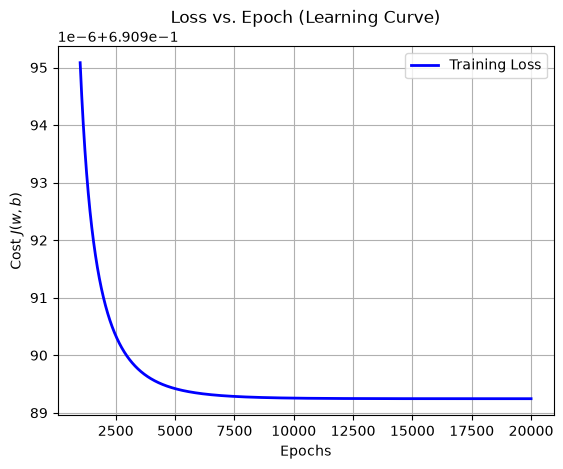

In [15]:
f_wb = np.dot(features, w) + b
#f_wb = np.clip(f_wb, -500, 500)
yPred = 1 / (1 + np.exp(-f_wb))
yPred = (yPred >= 0.5).astype(int)

# Confusian Matrix:
tp = np.sum((target == 1) & (yPred == 1))
tn = np.sum((target == 0) & (yPred == 0))
fp = np.sum((target == 0) & (yPred == 1))
fn = np.sum((target == 1) & (yPred == 0))

plt.plot(range(1000, len(J_history)), J_history[1000:], color='blue', linewidth=2, label='Training Loss')
plt.title('Loss vs. Epoch (Learning Curve)')
plt.xlabel('Epochs')
plt.ylabel('Cost $J(w,b)$')
plt.grid(True)
plt.legend()
plt.show()

In [17]:
f_wb = np.dot(testFeatures, w) + b
#f_wb = np.clip(f_wb, -500, 500)
predictedVal = 1 / (1 + np.exp(-f_wb))
predictedVal = (predictedVal >= 0.5).astype(int)

# Confusian Matrix:
tp = np.sum((testCases == 1) & (predictedVal == 1))
tn = np.sum((testCases == 0) & (predictedVal == 0))
fp = np.sum((testCases == 0) & (predictedVal == 1))
fn = np.sum((testCases == 1) & (predictedVal == 0))

accuracy = (tp + tn) / len(testCases) 
precision = tp / (tp + fp) 
recall = tp / (tp + fn)
f1 = 2 * (precision * recall) / (precision + recall)
testCost = costFunction(testFeatures, testCases, w, b)

print("TEST SET EVALUATION:")
print(f"Test Cost J(w,b)     : {testCost: .4f}")
print(f"Accuracy             : {accuracy * 100:.2f}%")
print(f"Precision            : {precision * 100:.2f}%")
print(f"Recall/Sensitivity   : {recall * 100:.2f}%")
print(f"F1 Score             : {f1: .4f}")

print("CONFUSION MATRIX:")
print(f"                  Pred Neg (0)   Pred Pos (1)")
print(f"Actual Neg (0)      {tn:8d}       {fp:8d}")
print(f"Actual Pos (1)      {fn:8d}       {tp:8d}")

TEST SET EVALUATION:
Test Cost J(w,b)     :  0.6968
Accuracy             : 48.91%
Precision            : 48.77%
Recall/Sensitivity   : 50.47%
F1 Score             :  0.4961
CONFUSION MATRIX:
                  Pred Neg (0)   Pred Pos (1)
Actual Neg (0)          1966           2186
Actual Pos (1)          2042           2081
